# 08 - Head comparison bar charts (NN and LR)

Grouped bar charts of fine-tuning accuracy by depth (last 1/2/3 blocks), drawn from the seeded
runs in `results_sensor/finetune_shared*.pt`.

**Chart A (NN head)** shows all three evaluation protocols side by side: the two single splits
(80/10/10, 70/15/15) and 5-fold CV. Only the CV bar carries an error bar (mean $\pm$ 1 std across
the 5 folds); the single splits are one number each, so they have no spread to show.

**Chart B (NN vs LR head)** compares the two readout heads under 5-fold CV. The single splits are
NN-only in the saved results (`run_split` never fits an LR head), so the head comparison is
restricted to CV, which is the trustworthy evaluation anyway.

Reference lines: frozen BrainOmni + LR (0.831) and handcrafted + LR (0.872).

In [1]:
import os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'
import numpy as np, torch
import matplotlib.pyplot as plt
OUT = '../results_sensor'
FROZEN_CV, HANDCRAFT_CV = 0.831, 0.872
NF = [10, 9, 8]                      # last 1, 2, 3 blocks
DEPTH_LABELS = ['Last 1 block', 'Last 2 blocks', 'Last 3 blocks']

MODELS = [('tiny', '',      'BrainOmni-tiny'),
          ('base', '_base', 'BrainOmni-base')]

data = {}
for tag, sfx, name in MODELS:
    path = f'{OUT}/finetune_shared{sfx}.pt'
    if not os.path.exists(path):
        print(f'skip {tag}: {path} not found'); continue
    d = torch.load(path, map_location='cpu', weights_only=False)
    data[tag] = d
    print(f'{name}: cv configs {sorted(d["cv"].keys())} | splits {list(d["nn_split"].keys())}')

BrainOmni-tiny: cv configs [8, 9, 10] | splits ['80/10/10', '70/15/15']
BrainOmni-base: cv configs [8, 9, 10] | splits ['80/10/10', '70/15/15']


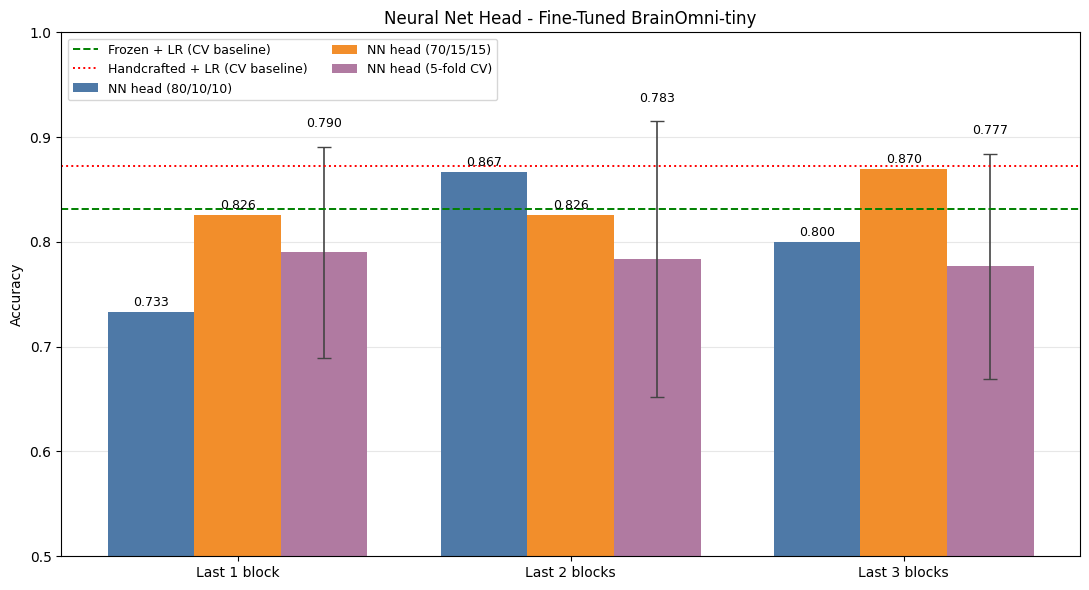

Saved head_nn_tiny.png | CV [0.79, 0.783, 0.777]


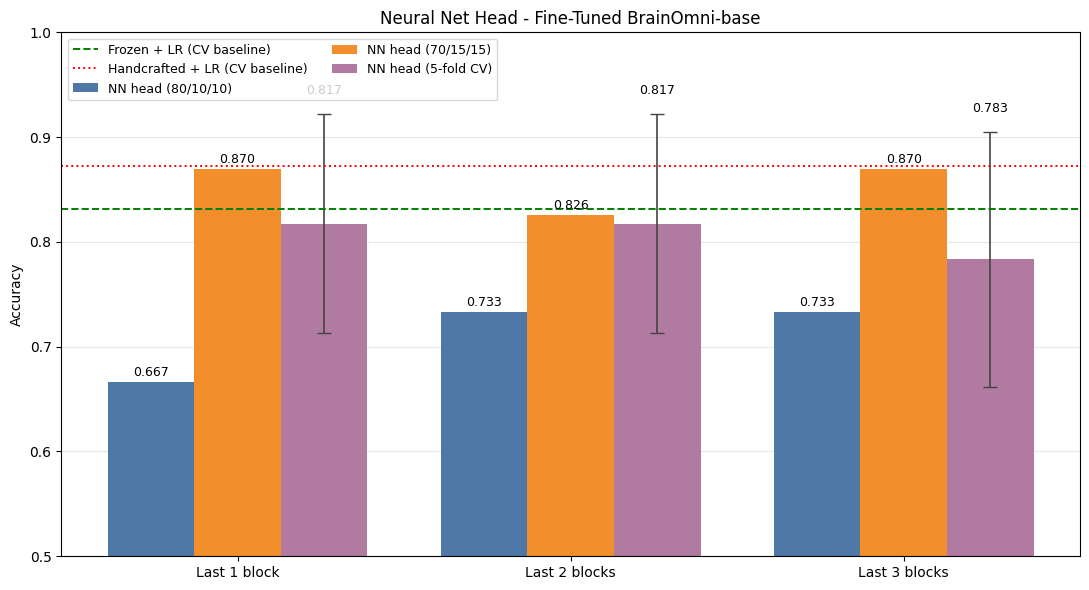

Saved head_nn_base.png | CV [0.817, 0.817, 0.783]


In [2]:
# Chart A: NN head, three evaluation protocols per depth
def chart_nn(d, model_name, fname):
    cv, ns = d['cv'], d['nn_split']
    split_names = ['80/10/10', '70/15/15']
    vals_80 = [ns['80/10/10'][nf]['test_acc'] for nf in NF] if ns else None
    vals_70 = [ns['70/15/15'][nf]['test_acc'] for nf in NF] if ns else None
    vals_cv = [cv[nf]['nn_mean'] for nf in NF]
    err_cv  = [np.std(cv[nf]['nn_folds']) for nf in NF]

    x = np.arange(3); w = 0.26
    fig, ax = plt.subplots(figsize=(11, 6))
    if vals_80 is not None:
        b1 = ax.bar(x - w, vals_80, w, color='#4E79A7', label='NN head (80/10/10)')
        b2 = ax.bar(x,     vals_70, w, color='#F28E2B', label='NN head (70/15/15)')
        ax.bar_label(b1, fmt='%.3f', fontsize=9, padding=2)
        ax.bar_label(b2, fmt='%.3f', fontsize=9, padding=2)
        xcv = x + w
    else:
        xcv = x
    b3 = ax.bar(xcv, vals_cv, w, yerr=err_cv, capsize=5, color='#B07AA1',
                error_kw=dict(lw=1.2, ecolor='#444'), label='NN head (5-fold CV)')
    ax.bar_label(b3, fmt='%.3f', fontsize=9, padding=12)

    ax.axhline(FROZEN_CV,    color='green', ls='--', lw=1.4, label='Frozen + LR (CV baseline)')
    ax.axhline(HANDCRAFT_CV, color='red',   ls=':',  lw=1.4, label='Handcrafted + LR (CV baseline)')
    ax.set_xticks(x); ax.set_xticklabels(DEPTH_LABELS)
    ax.set_ylabel('Accuracy'); ax.set_ylim(0.5, 1.0)
    ax.set_title(f'Neural Net Head - Fine-Tuned {model_name}')
    ax.legend(fontsize=9, ncol=2, loc='upper left'); ax.grid(axis='y', alpha=0.3); ax.set_axisbelow(True)
    plt.tight_layout(); plt.savefig(os.path.join(OUT, fname), dpi=150); plt.show()
    print('Saved', fname, '| CV', [round(v, 3) for v in vals_cv])

for tag, sfx, name in MODELS:
    if tag in data:
        chart_nn(data[tag], name, f'head_nn_{tag}.png')

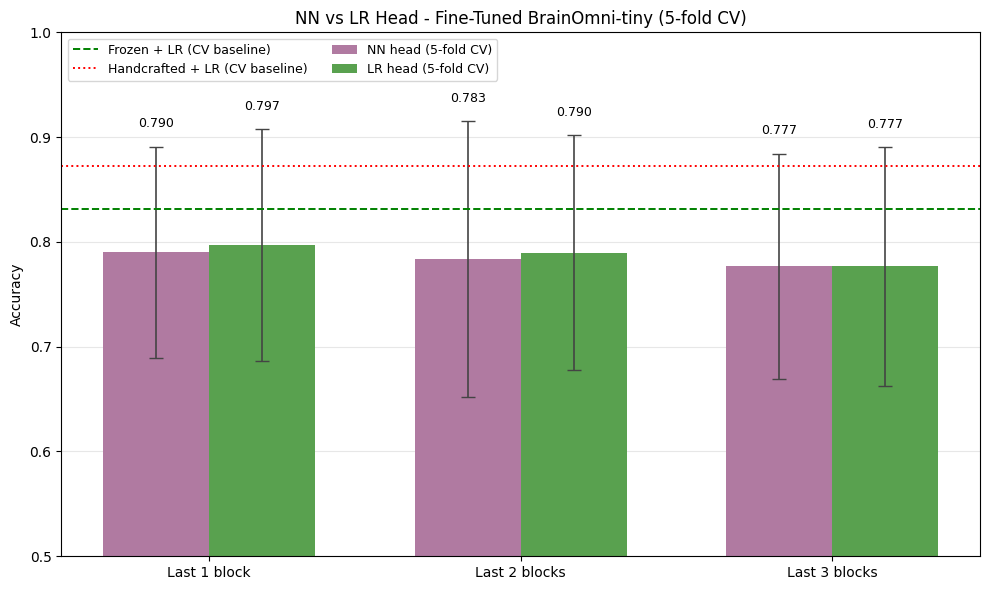

Saved head_nn_vs_lr_tiny.png | NN [0.79, 0.783, 0.777] | LR [0.797, 0.79, 0.777]


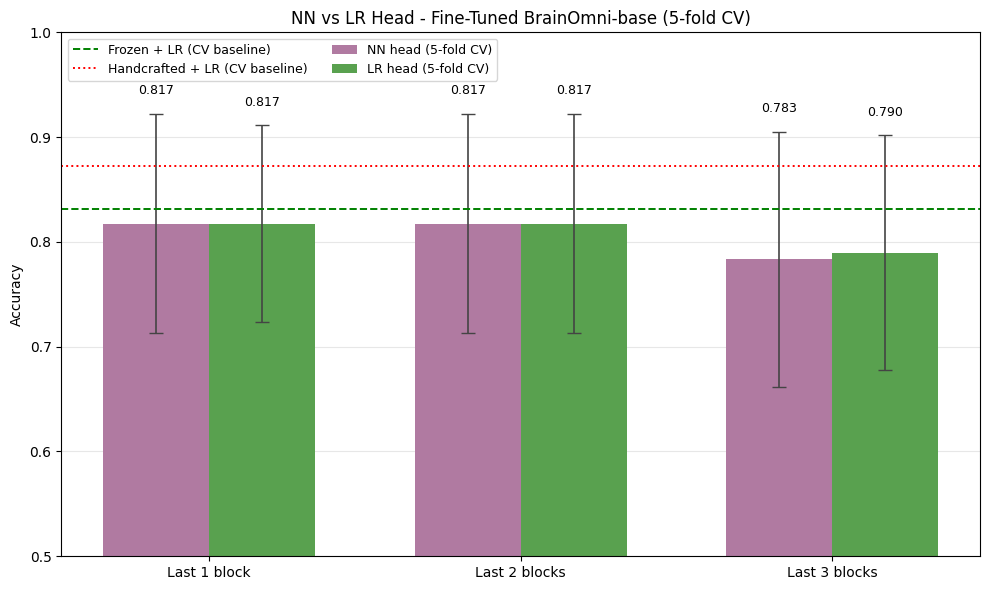

Saved head_nn_vs_lr_base.png | NN [0.817, 0.817, 0.783] | LR [0.817, 0.817, 0.79]


In [3]:
# Chart B: NN vs LR head, 5-fold CV (the only evaluation where both heads exist)
def chart_nn_vs_lr(d, model_name, fname):
    cv = d['cv']
    nn_v = [cv[nf]['nn_mean'] for nf in NF]
    nn_e = [np.std(cv[nf]['nn_folds']) for nf in NF]
    lr_v = [cv[nf]['lr_mean'] for nf in NF]
    lr_e = [np.std(cv[nf]['lr_folds']) for nf in NF]

    x = np.arange(3); w = 0.34
    fig, ax = plt.subplots(figsize=(10, 6))
    b1 = ax.bar(x - w/2, nn_v, w, yerr=nn_e, capsize=5, color='#B07AA1',
                error_kw=dict(lw=1.2, ecolor='#444'), label='NN head (5-fold CV)')
    b2 = ax.bar(x + w/2, lr_v, w, yerr=lr_e, capsize=5, color='#59A14F',
                error_kw=dict(lw=1.2, ecolor='#444'), label='LR head (5-fold CV)')
    ax.bar_label(b1, fmt='%.3f', fontsize=9, padding=12)
    ax.bar_label(b2, fmt='%.3f', fontsize=9, padding=12)

    ax.axhline(FROZEN_CV,    color='green', ls='--', lw=1.4, label='Frozen + LR (CV baseline)')
    ax.axhline(HANDCRAFT_CV, color='red',   ls=':',  lw=1.4, label='Handcrafted + LR (CV baseline)')
    ax.set_xticks(x); ax.set_xticklabels(DEPTH_LABELS)
    ax.set_ylabel('Accuracy'); ax.set_ylim(0.5, 1.0)
    ax.set_title(f'NN vs LR Head - Fine-Tuned {model_name} (5-fold CV)')
    ax.legend(fontsize=9, ncol=2, loc='upper left'); ax.grid(axis='y', alpha=0.3); ax.set_axisbelow(True)
    plt.tight_layout(); plt.savefig(os.path.join(OUT, fname), dpi=150); plt.show()
    print('Saved', fname, '| NN', [round(v,3) for v in nn_v], '| LR', [round(v,3) for v in lr_v])

for tag, sfx, name in MODELS:
    if tag in data:
        chart_nn_vs_lr(data[tag], name, f'head_nn_vs_lr_{tag}.png')

In [4]:
# Printed summary matching the depth table in the writeup
print(f'{"config":14s} {"last-1":>8} {"last-2":>8} {"last-3":>8}')
for tag, sfx, name in MODELS:
    if tag not in data: continue
    cv = data[tag]['cv']
    for head, key in [('NN', 'nn_mean'), ('LR', 'lr_mean')]:
        vals = [cv[nf][key] for nf in NF]
        print(f'{tag + " + " + head:14s} ' + ' '.join(f'{v:8.3f}' for v in vals))

config           last-1   last-2   last-3
tiny + NN         0.790    0.783    0.777
tiny + LR         0.797    0.790    0.777
base + NN         0.817    0.817    0.783
base + LR         0.817    0.817    0.790
